Importamos las librerias necesarias


In [1]:
import pandas as pd
import numpy as np 
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

In [ ]:
#abrimos los csv
from pathlib import Path
base_candidates = [Path('Recopilacion y almacenamiento de datos ') / 'data', Path('data')]
for base in base_candidates:
    if (base / 'moved_project_sql_result_01.csv').exists():
        companies = pd.read_csv(base / 'moved_project_sql_result_01.csv')
        barrios   = pd.read_csv(base / 'moved_project_sql_result_04.csv')
        break
else:
    raise FileNotFoundError('No se encontraron los CSV en la carpeta de datos esperada')
print(companies.head())
print(companies.info())
print('------------Separador-----------')
print(barrios.head())
print(barrios.info())



                      company_name  trips_amount
0                        Flash Cab         19558
1        Taxi Affiliation Services         11422
2                Medallion Leasing         10367
3                       Yellow Cab          9888
4  Taxi Affiliation Service Yellow          9299
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
None
------------Separador-----------
  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column 

Una vez revisado la info de los datos, vemos que el tipo y las entradas estan completas.

In [3]:
#Ordenamos los 10 barrios con mayor numero de viajes promedio 
top_10_barrios = barrios.sort_values(by='average_trips', ascending=False).head(10)
print(top_10_barrios)

  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000
5             Lake View    2420.966667
6            Grant Park    2068.533333
7         Museum Campus    1510.000000
8            Gold Coast    1364.233333
9    Sheffield & DePaul    1259.766667


Una vez ordenados los 10 barrios con mayor afluencia de viajes, graficamos. 


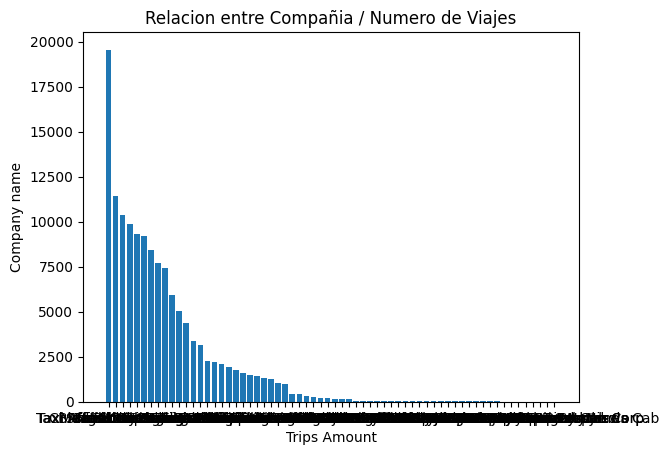

In [4]:
#grafico de compañias y numero de viajes
fig, ax=plt.subplots()
ax.bar(companies['company_name'],companies['trips_amount'])
ax.set_ylabel('Company name')
ax.set_xlabel('Trips Amount')
ax.set_title('Relacion entre Compañia / Numero de Viajes')
plt.show()

Debido a la cantidad de compañias el grafico no es entendible ni aporta ningun valor, por lo cual se hace un grafico de caja para observar la distribucion de los datos, y posteriormente un nuevo grafico de barras mas selectivo, con los top 10 performes de las compañias. 

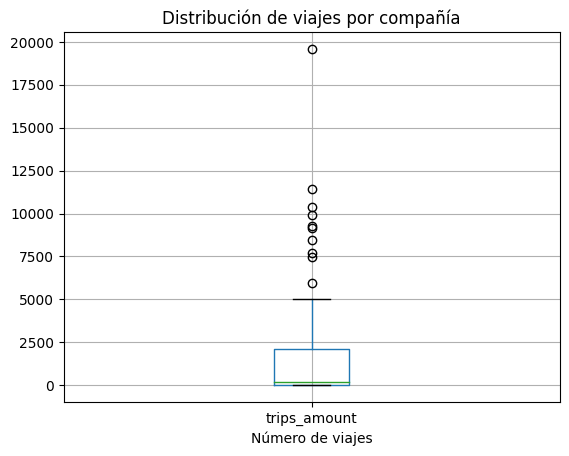

In [5]:
#Box plot para ver la disribucion de los datos 
companies.boxplot(column='trips_amount')
plt.xlabel('Número de viajes')
plt.title('Distribución de viajes por compañía')
plt.show()


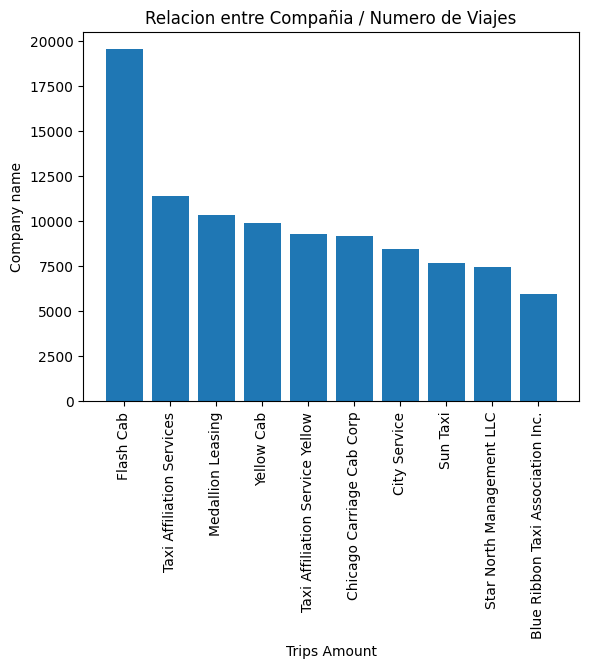

In [6]:
#Hacemos un gratico con los 10 compañias que generan mas viajes 
top_10_companies= companies.sort_values(by='trips_amount', ascending=False).head(10)
fig, ax=plt.subplots()
ax.bar(top_10_companies['company_name'],top_10_companies['trips_amount'])
ax.set_ylabel('Company name')
ax.set_xlabel('Trips Amount')
ax.set_title('Relacion entre Compañia / Numero de Viajes')
plt.xticks(rotation=90)
plt.show()


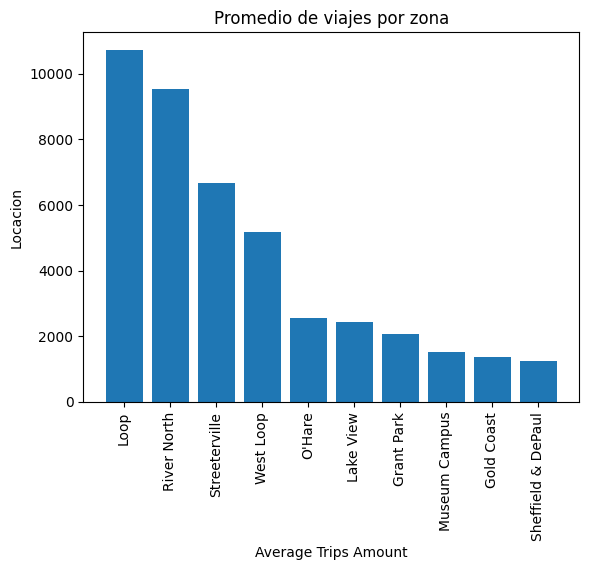

In [7]:
#Ahora graficamos los 10 barrios con mas viajes 

fig, ax=plt.subplots()
ax.bar(top_10_barrios['dropoff_location_name'],top_10_barrios['average_trips'])
ax.set_ylabel('Locacion')
ax.set_xlabel('Average Trips Amount')
ax.set_title('Promedio de viajes por zona')
plt.xticks(rotation=90)
plt.show()



Como podemos observar en el grafico de compañias,Flash Cab esta muy alejado de la competencia,y eso solo tomando en cuenta a los top 10 performers, esto podria deberse a muchas razones, por mecionar algunas, puede ser por disponibilidad de servicio, areas de cobertura, precio, entre otras, debido a las limitantes del data frame no es posible hacer una exploracion mas a profundiad. 

En cuanto al grafico de top 10 barrios podemos observar que las cantidades de viajes vairan mucho de unas zonas a otras por las que podriamos clasificarlas como de alta demanda y baja demanda para otros analisis, o toma decisiones, por ejemplo si dirigir un mayor numero de conductores hacia esas zonas, verificar si los productos se adecuan a las difernets localidades(por ejemplo zonas con ingresos mas altos o mas bajos), entre otros. 




In [ ]:
#importamos un tercer data frame
from pathlib import Path
base_candidates = [Path('Recopilacion y almacenamiento de datos ') / 'data', Path('data')]
for base in base_candidates:
    if (base / 'moved_project_sql_result_07.csv').exists():
        loop_to_ohare = pd.read_csv(base / 'moved_project_sql_result_07.csv')
        break
else:
    raise FileNotFoundError('No se encontró moved_project_sql_result_07.csv en la carpeta de datos esperada')
print(loop_to_ohare.head())


              start_ts weather_conditions  duration_seconds
0  2017-11-25 16:00:00               Good            2410.0
1  2017-11-25 14:00:00               Good            1920.0
2  2017-11-25 12:00:00               Good            1543.0
3  2017-11-04 10:00:00               Good            2512.0
4  2017-11-11 07:00:00               Good            1440.0


Hipotesis nula, la duracion de un viaje desde Loop al aeropuerto de O'Hare es la misma los sabados, sin importar si llueve o no.

Hipotesis alternativa, la duracion de un viaje desde Loop al aeropuerto O'Hare es diferente los sabados cuando llueve. 

In [9]:
#clasificamos los datos en sabados lluviosos y no lluviosos
loop_to_ohare['start_ts'] = pd.to_datetime(loop_to_ohare['start_ts'])
saturdays = loop_to_ohare[loop_to_ohare['start_ts'].dt.dayofweek == 5]
print(saturdays.head(10))

sabados_sin_lluvia= saturdays[saturdays['weather_conditions'] == 'Good']
sabados_con_lluvia= saturdays[saturdays['weather_conditions'] == 'Bad']

             start_ts weather_conditions  duration_seconds
0 2017-11-25 16:00:00               Good            2410.0
1 2017-11-25 14:00:00               Good            1920.0
2 2017-11-25 12:00:00               Good            1543.0
3 2017-11-04 10:00:00               Good            2512.0
4 2017-11-11 07:00:00               Good            1440.0
5 2017-11-11 04:00:00               Good            1320.0
6 2017-11-04 16:00:00                Bad            2969.0
7 2017-11-18 11:00:00               Good            2280.0
8 2017-11-11 14:00:00               Good            2460.0
9 2017-11-11 12:00:00               Good            2040.0


In [10]:
#ejecutamos una prueba tstudent de variables independientes


#duraciones por grupo
duracion_con_lluvia= sabados_con_lluvia['duration_seconds']
duracion_sin_lluvia= sabados_sin_lluvia['duration_seconds']

#prueba tstudend para muestras independientes.
t_stat, p_value= ttest_ind(duracion_con_lluvia, duracion_sin_lluvia)

print(f'Estadistico t: {t_stat:.2f}')
print(f'valor p: {p_value:.6f}')

alpha = 0.05

if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay diferencia significativa.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente.")



Estadistico t: 6.95
valor p: 0.000000
Rechazamos la hipótesis nula: hay diferencia significativa.


De acuerdo a la prueba estadistica descartamos la hipotesis nula ya que ed acuerdo al tstudent test, la diferencia es significativa por lo que no podemos atribuirsela a la casualidad. 

En este caso se utilizo apha en 0.05 por que es un estandar comun para este tipo de pruebas. 